10. représente que 40 départements sur 96 sont présents dans le dataset final. 
Pour couvrir l'ensemble des départements métropolitains à partir des 40 départements disposant de stations, la méthode la plus rigoureuse et rapide consiste à faire une imputation par le voisin le plus proche (Nearest Neighbor) en se basant sur les coordonnées géographiques (centroïdes) des départements.

In [66]:
#import librairie nécessaire
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [67]:
df_meteo_hebdo_clean_40 = pd.read_csv("../data/processed/5.df_meteo_hebdo_clean_40.csv")

df_meteo_hebdo_clean_40.info()

<class 'pandas.DataFrame'>
RangeIndex: 8400 entries, 0 to 8399
Data columns (total 27 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   code_dept                                   8400 non-null   str    
 1   annee_semaine                               8400 non-null   str    
 2   latitude                                    8400 non-null   float64
 3   longitude                                   8400 non-null   float64
 4   pression_mer                                8400 non-null   float64
 5   tendance_pression_3h                        8400 non-null   float64
 6   vent_direction                              8400 non-null   float64
 7   vent_vitesse                                8400 non-null   float64
 8   temperature_kelvin                          8400 non-null   float64
 9   humidite_relative                           8400 non-null   float64
 10  visibilite             

In [68]:

df_meteo_hebdo_clean_40.head()

,code_dept,annee_semaine,latitude,longitude,pression_mer,tendance_pression_3h,vent_direction,vent_vitesse,temperature_kelvin,humidite_relative,...,precipitation_24h,tp_averses_ou_orages,tp_brouillard,tp_brume_fumee_ou_phenomenes_particuliers,tp_neige_precipitation_solide,tp_phenomenes_recents_derniere_heure,tp_pluie_ou_bruine,tp_sans_precipitation_visibilite_ou_nuages,tp_tempete_poussiere_chasse_neige,tp_temps_inconnu
0,05,2020-W53,44.571167,6.508667,101740.0,-1.250000,139.583333,3.458333,273.425000,75.208333,...,18.5,0.0,0.0,0.0,2.0,0.0,0.0,22.0,0.0,0.0
1,05,2021-W01,44.571167,6.508667,101740.0,11.071429,106.071429,3.214286,271.585714,59.089286,...,5.5,0.0,0.0,0.0,3.0,0.0,0.0,53.0,0.0,0.0
2,05,2021-W02,44.571167,6.508667,101740.0,10.000000,94.821429,0.892857,271.876786,70.410714,...,-0.8,0.0,0.0,0.0,0.0,0.0,0.0,56.0,0.0,0.0
3,05,2021-W03,44.571167,6.508667,101740.0,-25.535714,124.285714,1.696429,274.296429,70.553571,...,191.4,0.0,0.0,0.0,3.0,0.0,6.0,47.0,0.0,0.0
4,05,2021-W04,44.571167,6.508667,101740.0,-7.500000,151.964286,1.607143,274.371429,73.767857,...,262.7,0.0,1.0,0.0,3.0,0.0,4.0,48.0,0.0,0.0


In [69]:
df_meteo_hebdo_clean_40['code_dept'].unique()

<StringArray>
['05', '06', '09', '10', '12', '13', '14', '17', '18', '21', '22', '26', '29',
 '2A', '2B', '31', '33', '34', '35', '37', '40', '43', '44', '46', '50', '51',
 '54', '59', '61', '63', '65', '66', '67', '68', '69', '76', '80', '86', '87',
 '91']
Length: 40, dtype: str

Pour étendre votre couverture de 40 à 96 départements avant la fusion avec les données épidémiologiques, la meilleure approche consiste à réaliser une imputation spatiale (interpolation géographique) semaine par semaine.

Pour chaque semaine, on prend un département sans mesure et on lui attribue simplement la valeur du département mesuré le plus proche géographiquement.


In [70]:
from sklearn.neighbors import NearestNeighbors


# Supprimer les anciennes colonnes de coordonnées si elles existent dans le fichier d'origine 
# pour éviter les collisions (_x, _y) avec la grille de référence.
cols_a_nettoyer = [col for col in df_meteo_hebdo_clean_40.columns if col in ['latitude', 'longitude', 'lat', 'lon']]
df_meteo_hebdo_clean_40 = df_meteo_hebdo_clean_40.drop(columns=cols_a_nettoyer, errors='ignore')

# 2. Table de référence des 96 départements et de leurs coordonnées officielles
coords_depts_data = {
    'code_dept': [
        '01','02','03','04','05','06','07','08','09','10','11','12','13','14','15','16','17','18','19','2A','2B',
        '21','22','23','24','25','26','27','28','29','30','31','32','33','34','35','36','37','38','39','40',
        '41','42','43','44','45','46','47','48','49','50','51','52','53','54','55','56','57','58','59','60',
        '61','62','63','64','65','66','67','68','69','70','71','72','73','74','75','76','77','78','79','80',
        '81','82','83','84','85','86','87','88','89','90','91','92','93','94','95'
    ],
    'latitude': [
        46.2056,49.5667,46.3333,44.0931,44.5561,43.7102,44.7333,49.7500,42.9600,48.3000,43.2100,44.3500,43.2965,
        49.1828,45.0333,45.6500,45.7485,47.0833,45.2667,41.9192,42.2681,47.3220,48.5147,46.1667,45.1833,47.2478,
        44.9333,49.0238,48.4451,48.3904,43.8367,43.6045,43.6464,44.8378,43.6108,48.1119,46.8111,47.3941,45.1885,
        46.6833,43.7167,47.5833,45.4333,45.0500,47.2184,47.9029,44.4500,44.2000,44.5167,47.4712,49.1167,49.2583,
        48.1000,48.0700,48.6921,49.1667,47.6586,49.1193,46.9833,50.6292,49.4333,48.4333,50.4167,45.7797,43.2965,
        43.2333,42.6986,48.5734,47.7500,45.7640,47.6167,46.3833,48.0061,45.5667,45.9000,48.8566,49.4431,48.5446,
        48.8014,46.3256,49.8942,43.9292,44.0167,43.3500,43.9493,46.6705,46.5802,45.8338,48.1716,47.7986,47.6433,
        48.6244,48.8923,48.9138,48.7890,49.0384
    ],
    'longitude': [
        5.2300,3.6167,3.1333,6.0856,6.0719,7.2620,4.7500,4.7167,1.5300,4.0833,2.3500,2.5667,5.3698,
        0.3706,2.4333,0.1500,-1.1486,2.4000,1.8167,8.8739,8.5622,5.0415,2.1364,2.1667,0.7333,6.0245,
        4.8933,1.1408,1.4881,-4.4889,4.3600,1.4442,0.5831,-0.5792,3.8767,-1.6743,1.6917,0.6848,5.7245,
        5.5500,-1.0500,1.3333,4.3833,3.5333,-1.5536,1.9039,1.4333,0.6167,3.5000,-0.5514,-1.0833,4.0311,
        5.2667,-0.7700,6.1844,5.4167,-2.7539,6.1757,3.1667,3.0573,2.4833,0.5667,2.7833,3.0870,-0.3666,
        0.0833,2.8956,7.7521,7.3333,4.8357,6.1500,4.8500,0.2000,5.9166,6.5500,2.3522,1.0993,2.6506,
        2.1301,-0.4678,2.3028,2.1497,1.3500,6.1333,4.8000,-1.4233,0.3403,1.2611,6.4500,3.5644,6.8651,
        2.4450,2.2211,2.4491,2.4500,2.1054
    ]
}
df_coords = pd.DataFrame(coords_depts_data)

# 3. Créer la grille complète (Toutes les semaines x les 96 départements)
toutes_semaines = df_meteo_hebdo_clean_40['annee_semaine'].unique()
grille_complete = pd.MultiIndex.from_product(
    [toutes_semaines, df_coords['code_dept']], 
    names=['annee_semaine', 'code_dept']
).to_frame(index=False)

# Fusionner proprement avec les coordonnées uniques et propres
grille_complete = grille_complete.merge(df_coords, on='code_dept', how='left')
df_complet = grille_complete.merge(df_meteo_hebdo_clean_40, on=['annee_semaine', 'code_dept'], how='left')

# 4. Identifier les variables météo numériques à extrapoler
cols_a_ignorer = ['annee_semaine', 'code_dept', 'latitude', 'longitude', 'annee', 'semaine']
cols_meteo = [col for col in df_complet.columns if col not in cols_a_ignorer and pd.api.types.is_numeric_dtype(df_complet[col])]

# 5. Imputation semaine par semaine par position numpy
dfs_finales = []

for semaine, df_sem in df_complet.groupby('annee_semaine'):
    df_sem = df_sem.copy()
    
    # Masque des lignes ayant des données d'origine
    mask_connus = df_sem[cols_meteo[0]].notna()
    
    if mask_connus.any() and (~mask_connus).any():
        connus = df_sem[mask_connus].reset_index(drop=True)
        inconnus = df_sem[~mask_connus].reset_index(drop=True)
        
        nn = NearestNeighbors(n_neighbors=1, algorithm='ball_tree')
        nn.fit(connus[['latitude', 'longitude']].values)
        
        _, indices = nn.kneighbors(inconnus[['latitude', 'longitude']].values)
        indices = indices.flatten()
        
        idx_inconnus = df_sem.index[~mask_connus]
        for col in cols_meteo:
            if col in connus.columns:
                df_sem.loc[idx_inconnus, col] = connus[col].values[indices]
                
    dfs_finales.append(df_sem)

# 6. Assemblage final et export
df_meteo_hebdo_clean_96 = pd.concat(dfs_finales, ignore_index=True)

print("Extrapolation spatiale corrigée et terminée avec succès !")
print(f"Dimensions finales : {df_meteo_hebdo_clean_96.shape}")
print(f"Nombre total de valeurs manquantes restantes : {df_meteo_hebdo_clean_96[cols_meteo].isna().sum().sum()}")

Extrapolation spatiale corrigée et terminée avec succès !
Dimensions finales : (20160, 27)
Nombre total de valeurs manquantes restantes : 0


In [71]:
df_meteo_hebdo_clean_40.info()


<class 'pandas.DataFrame'>
RangeIndex: 8400 entries, 0 to 8399
Data columns (total 25 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   code_dept                                   8400 non-null   str    
 1   annee_semaine                               8400 non-null   str    
 2   pression_mer                                8400 non-null   float64
 3   tendance_pression_3h                        8400 non-null   float64
 4   vent_direction                              8400 non-null   float64
 5   vent_vitesse                                8400 non-null   float64
 6   temperature_kelvin                          8400 non-null   float64
 7   humidite_relative                           8400 non-null   float64
 8   visibilite                                  8400 non-null   float64
 9   pression_station                            8400 non-null   float64
 10  periode_rafale         

In [72]:
df_meteo_hebdo_clean_96.info()

<class 'pandas.DataFrame'>
RangeIndex: 20160 entries, 0 to 20159
Data columns (total 27 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   annee_semaine                               20160 non-null  str    
 1   code_dept                                   20160 non-null  str    
 2   latitude                                    20160 non-null  float64
 3   longitude                                   20160 non-null  float64
 4   pression_mer                                20160 non-null  float64
 5   tendance_pression_3h                        20160 non-null  float64
 6   vent_direction                              20160 non-null  float64
 7   vent_vitesse                                20160 non-null  float64
 8   temperature_kelvin                          20160 non-null  float64
 9   humidite_relative                           20160 non-null  float64
 10  visibilite           

In [73]:
df_meteo_hebdo_clean_96.head(10)

,annee_semaine,code_dept,latitude,longitude,pression_mer,tendance_pression_3h,vent_direction,vent_vitesse,temperature_kelvin,humidite_relative,...,precipitation_24h,tp_averses_ou_orages,tp_brouillard,tp_brume_fumee_ou_phenomenes_particuliers,tp_neige_precipitation_solide,tp_phenomenes_recents_derniere_heure,tp_pluie_ou_bruine,tp_sans_precipitation_visibilite_ou_nuages,tp_tempete_poussiere_chasse_neige,tp_temps_inconnu
0,2020-W53,01,46.2056,5.2300,101025.833333,27.500000,320.833333,4.958333,274.637500,88.125000,...,124.5,0.0,0.0,0.0,1.0,3.0,3.0,17.0,0.0,0.0
1,2020-W53,02,49.5667,3.6167,101285.000000,34.583333,207.916667,1.125000,274.375000,93.541667,...,21.1,0.0,4.0,3.0,0.0,0.0,1.0,16.0,0.0,0.0
2,2020-W53,03,46.3333,3.1333,101203.333333,22.916667,222.500000,2.041667,273.545833,78.875000,...,14.2,0.0,0.0,1.0,0.0,0.0,0.0,23.0,0.0,0.0
3,2020-W53,04,44.0931,6.0856,101740.000000,-1.250000,139.583333,3.458333,273.425000,75.208333,...,18.5,0.0,0.0,0.0,2.0,0.0,0.0,22.0,0.0,0.0
4,2020-W53,05,44.5561,6.0719,101740.000000,-1.250000,139.583333,3.458333,273.425000,75.208333,...,18.5,0.0,0.0,0.0,2.0,0.0,0.0,22.0,0.0,0.0
5,2020-W53,06,43.7102,7.2620,100464.583333,-0.833333,164.166667,4.833333,280.754167,82.166667,...,500.5,3.0,0.0,0.0,0.0,3.0,14.0,4.0,0.0,0.0
6,2020-W53,07,44.7333,4.7500,100798.333333,17.500000,28.750000,5.791667,277.000000,76.208333,...,75.9,0.0,0.0,0.0,0.0,0.0,3.0,21.0,0.0,0.0
7,2020-W53,08,49.7500,4.7167,101285.000000,34.583333,207.916667,1.125000,274.375000,93.541667,...,21.1,0.0,4.0,3.0,0.0,0.0,1.0,16.0,0.0,0.0
8,2020-W53,09,42.9600,1.5300,101239.166667,12.916667,192.916667,1.416667,274.237500,84.791667,...,34.2,0.0,0.0,0.0,1.0,0.0,0.0,23.0,0.0,0.0
9,2020-W53,10,48.3000,4.0833,101297.916667,30.416667,306.666667,1.625000,273.662500,94.166667,...,6.8,0.0,1.0,14.0,1.0,0.0,1.0,7.0,0.0,0.0


1. La vérification stricte (zéro modification des départements d'origine)
Ce script recharge ton fichier de départ (5.df_meteo_hebdo_clean_40.csv) et le compare point par point avec le fichier final sur les 40 départements initiaux. Si l'écart maximal est de 0.0, cela prouve que tes vraies mesures n'ont pas été modifiées.

In [74]:
import pandas as pd

# Fusionner sur la semaine et le département pour comparer uniquement les 40 d'origine
comparaison = df_meteo_hebdo_clean_40.merge(
    df_meteo_hebdo_clean_96, 
    on=['annee_semaine', 'code_dept'], 
    suffixes=('_orig', '_final')
)

# Exclure explicitement les colonnes non-météo ou de coordonnées
exclus = ['annee_semaine', 'code_dept', 'annee', 'semaine', 'latitude', 'longitude']
cols_meteo = [c for c in df_meteo_hebdo_clean_40.columns if c not in exclus]

toutes_identiques = True
for col in cols_meteo:
    col_orig = f'{col}_orig'
    col_final = f'{col}_final'
    
    # On s'assure que les colonnes suffixées existent bien avant de comparer
    if col_orig in comparaison.columns and col_final in comparaison.columns:
        if pd.api.types.is_numeric_dtype(comparaison[col_orig]):
            ecart = (comparaison[col_orig] - comparaison[col_final]).abs().max()
            if ecart > 1e-6:
                print(f"ALERTE : Différence détectée sur {col} (écart max : {ecart})")
                toutes_identiques = False

if toutes_identiques:
    print("Vérification validée : Aucune valeur des départements d'origine n'a été modifiée !")

Vérification validée : Aucune valeur des départements d'origine n'a été modifiée !


In [75]:
import pandas as pd

# Choisir une semaine de test (par exemple la première disponible)
semaine_test = df_meteo_hebdo_clean_96['annee_semaine'].iloc[0]

# Filtrer pour la semaine choisie
df_sem_test = df_meteo_hebdo_clean_96[df_meteo_hebdo_clean_96['annee_semaine'] == semaine_test]

# Nom exact de la variable de pression (à adapter si besoin selon tes colonnes)
var_pression = 'tendance_pression_3h'

print(f"--- OBSERVATION POUR LA SEMAINE : {semaine_test} ---")
if var_pression in df_sem_test.columns:
    # Afficher tous les départements (de 01 à 95) pour cette variable
    resultats = df_sem_test[['code_dept', var_pression]].sort_values('code_dept')
    print(resultats.to_string(index=False))
else:
    print(f"Attention, la colonne '{var_pression}' n'a pas été trouvée. Voici les colonnes disponibles :")
    print(df_meteo_hebdo_clean_96.columns.tolist())

--- OBSERVATION POUR LA SEMAINE : 2020-W53 ---
code_dept  tendance_pression_3h
       01             27.500000
       02             34.583333
       03             22.916667
       04             -1.250000
       05             -1.250000
       06             -0.833333
       07             17.500000
       08             34.583333
       09             12.916667
       10             30.416667
       11             22.083333
       12             12.500000
       13              6.250000
       14             35.000000
       15             12.500000
       16             22.083333
       17             13.043478
       18             24.166667
       19             18.333333
       21             27.916667
       22             32.916667
       23             24.166667
       24             18.333333
       25             27.916667
       26             17.500000
       27             33.333333
       28             32.916667
       29             33.750000
       2A             -7.

In [76]:
df_meteo_hebdo_clean_96.to_csv("../data/processed/df_meteo_hebdo_clean_96.csv", index=False, encoding='utf-8')

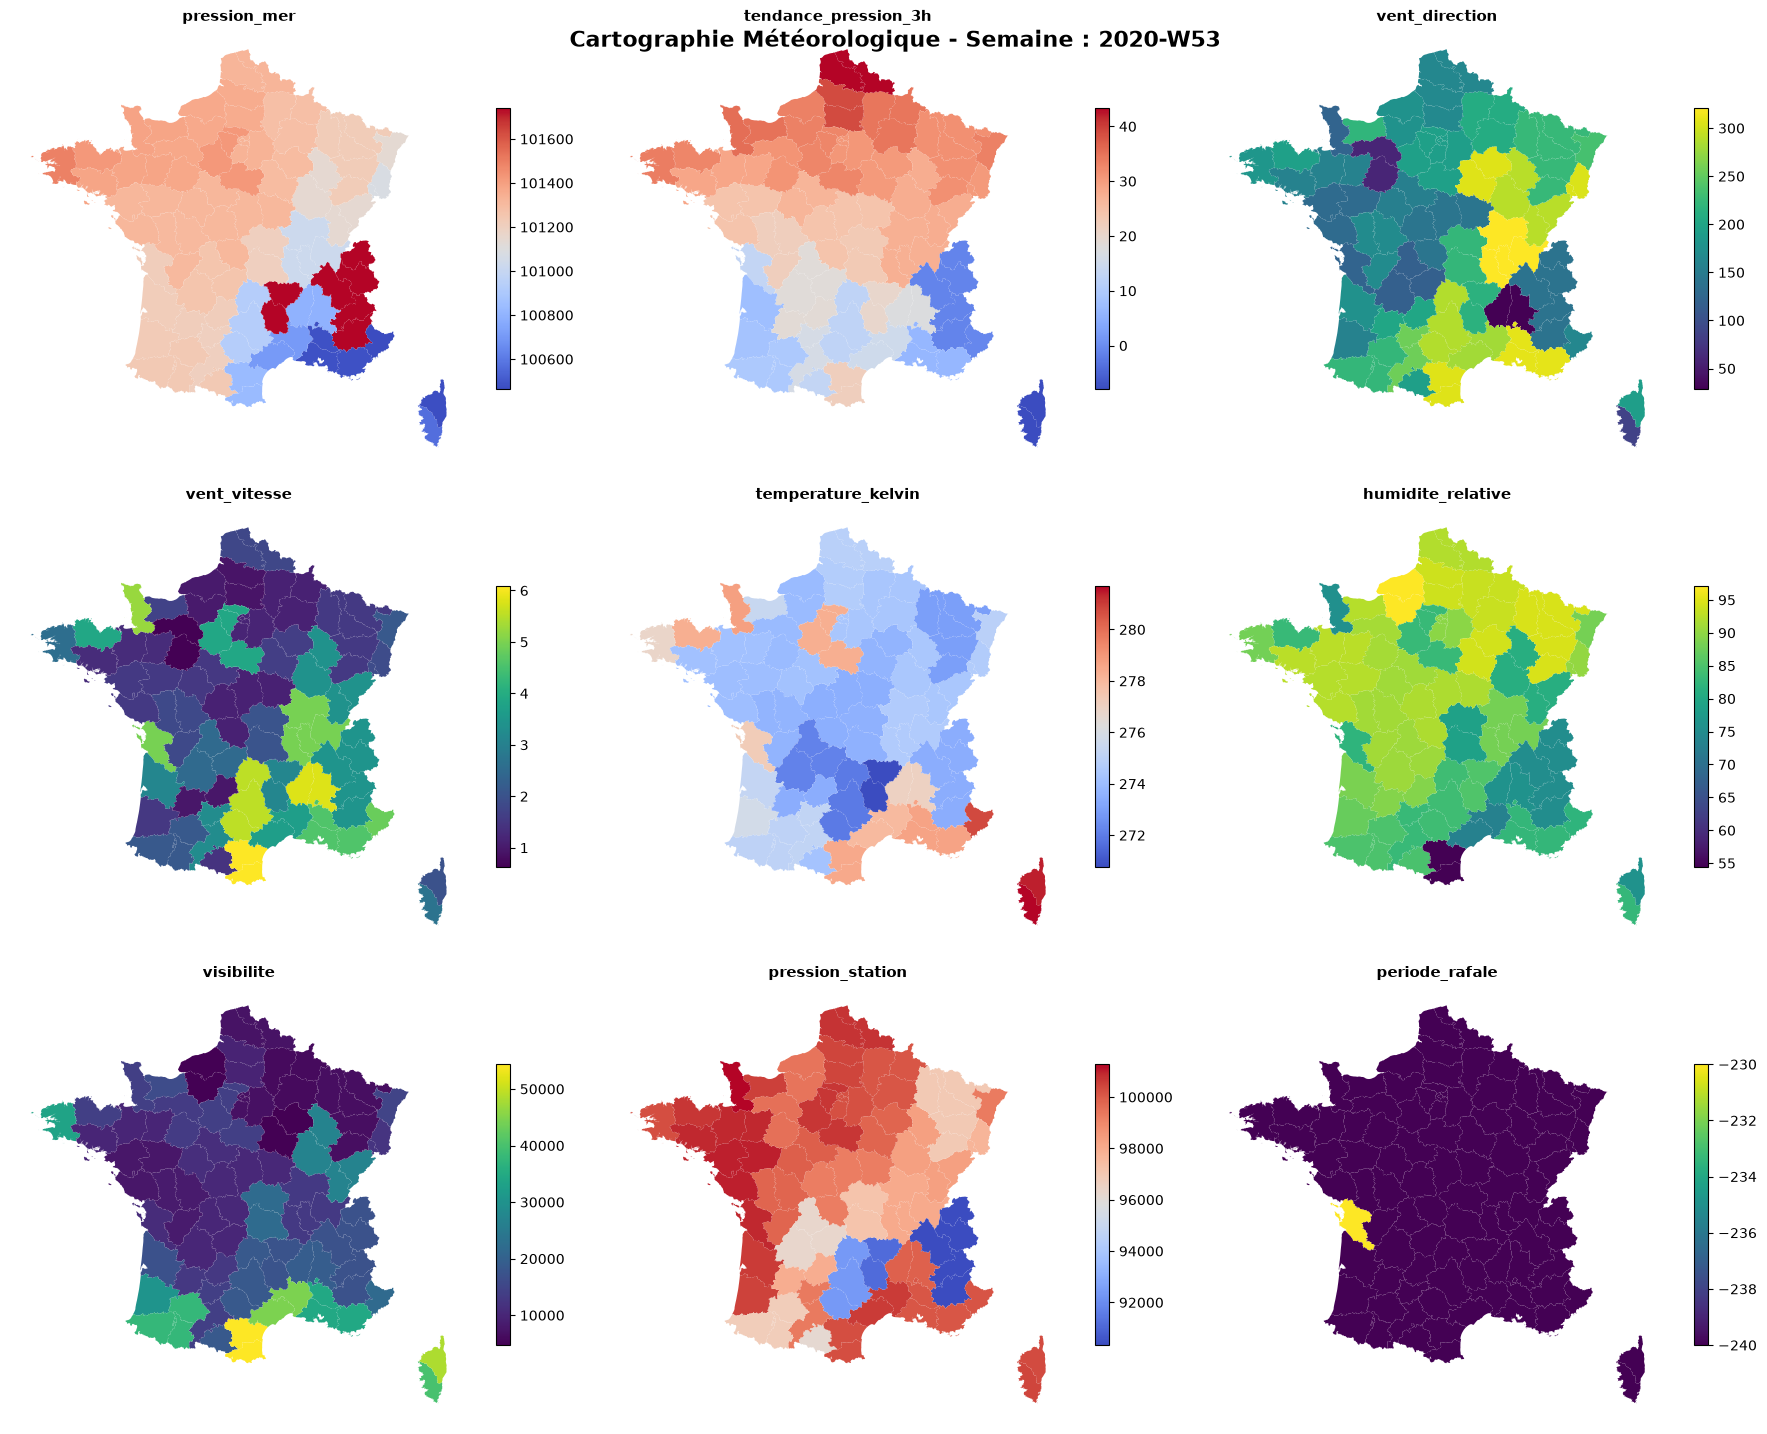

In [78]:
import geopandas as gpd
import matplotlib.pyplot as plt

# 1. Charger votre dataset final des 96 départements
df_96 = pd.read_csv("../data/processed/df_meteo_hebdo_clean_96.csv", dtype={'code_dept': str})

# 2. Charger le fond de carte GeoJSON des départements français
url_geojson = "https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/departements.geojson"
gdf_depts = gpd.read_file(url_geojson)

# Le champ code département s'appelle souvent 'code' dans ce GeoJSON, on l'uniformise
gdf_depts['code_dept'] = gdf_depts['code'].astype(str).str.zfill(2)

# 3. Choisir une semaine à visualiser (par exemple, la première disponible)
semaine_cible = df_96['annee_semaine'].iloc[0]
df_semaine = df_96[df_96['annee_semaine'] == semaine_cible]

# Fusionner les données météo avec le fond de carte géographique
map_df = gdf_depts.merge(df_semaine, on='code_dept', how='left')

# 4. Définir la liste des 9éme variables à afficher
variables = [
    'pression_mer', 'tendance_pression_3h', 'vent_direction', 
    'vent_vitesse', 'temperature_kelvin', 'humidite_relative', 
    'visibilite', 'pression_station', 'periode_rafale'
]

# Filtrer pour ne garder que celles présentes dans le DataFrame
variables_dispo = [v for v in variables if v in map_df.columns]

# 5. Création de la grille de subplots (3 lignes x 3 colonnes)
nb_vars = len(variables_dispo)
fig, axes = plt.subplots(3, 3, figsize=(18, 15))
axes = axes.flatten()

for i, var in enumerate(variables_dispo):
    ax = axes[i]
    # Tracer la carte choroplèthe
    map_df.plot(
        column=var,
        ax=ax,
        cmap='coolwarm' if 'temperature' in var or 'pression' in var else 'viridis',
        legend=True,
        legend_kwds={'shrink': 0.6},
        missing_kwds={'color': 'lightgrey'} # Couleur si données manquantes
    )
    ax.set_title(f"{var}", fontsize=11, fontweight='bold')
    ax.axis('off')

# Masquer les axes s'il reste des subplots vides
for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.suptitle(f"Cartographie Météorologique - Semaine : {semaine_cible}", fontsize=16, fontweight='bold', y=0.95)
plt.tight_layout()
plt.show()

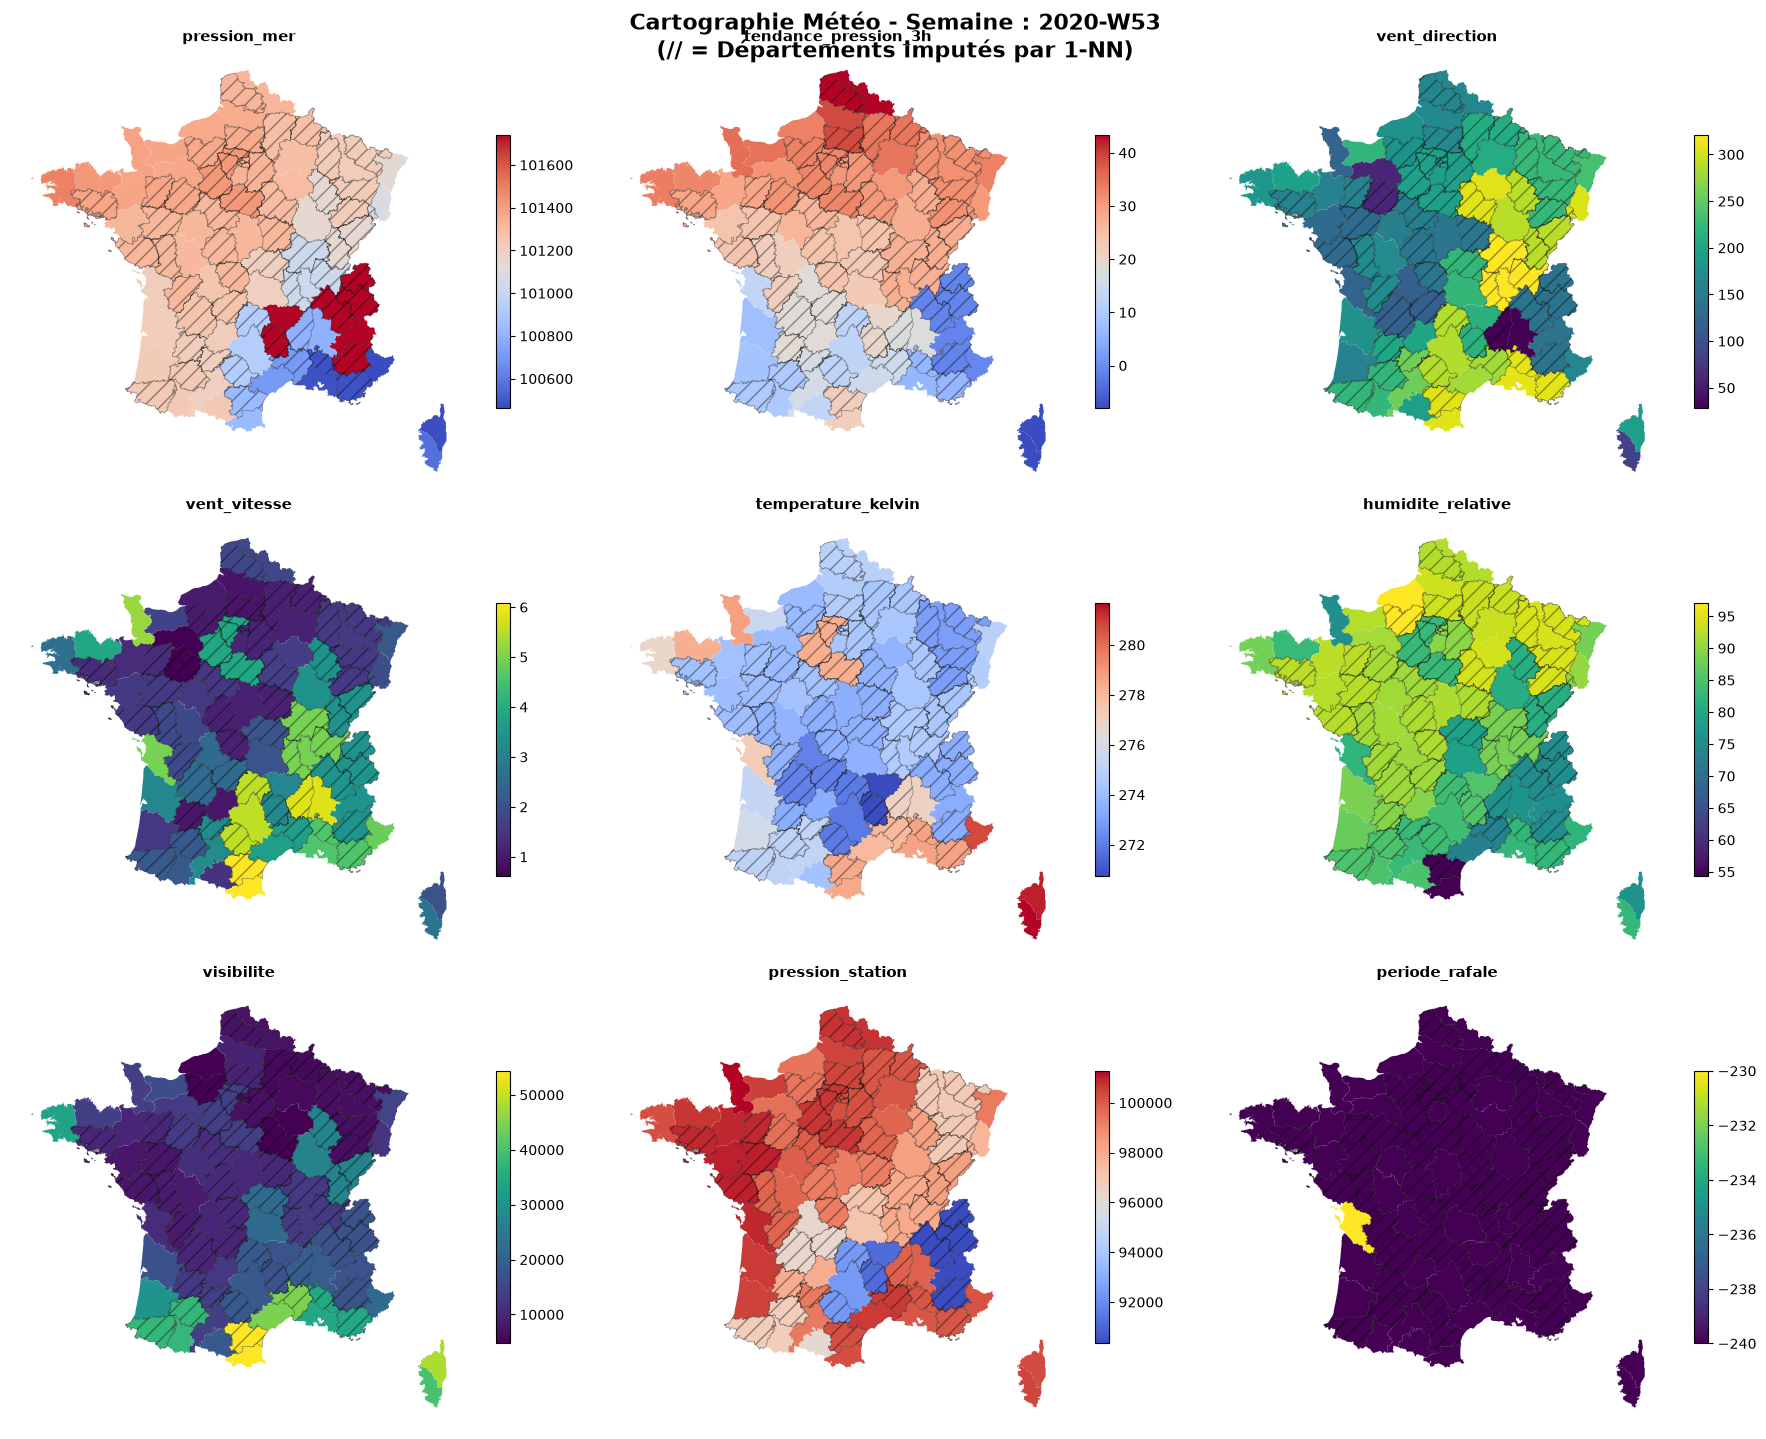

In [79]:
# 1. Charger les deux jeux de données
df_40 = pd.read_csv("../data/processed/5.df_meteo_hebdo_clean_40.csv", dtype={'code_dept': str})
depts_origine = set(df_40['code_dept'].str.strip().str.zfill(2).unique())

df_96 = pd.read_csv("../data/processed/df_meteo_hebdo_clean_96.csv", dtype={'code_dept': str})
df_96['code_dept'] = df_96['code_dept'].str.strip().str.zfill(2)

# 2. Charger le fond de carte GeoJSON
url_geojson = "https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/departements.geojson"
gdf_depts = gpd.read_file(url_geojson)
gdf_depts['code_dept'] = gdf_depts['code'].astype(str).str.zfill(2)

# 3. Filtrer sur une semaine cible
semaine_cible = df_96['annee_semaine'].iloc[0]
df_semaine = df_96[df_96['annee_semaine'] == semaine_cible]

# Fusionner avec la carte
map_df = gdf_depts.merge(df_semaine, on='code_dept', how='left')

# Identifier les départements imputés
map_df['est_impute'] = ~map_df['code_dept'].isin(depts_origine)

# 4. Variables à afficher
variables = [
    'pression_mer', 'tendance_pression_3h', 'vent_direction', 
    'vent_vitesse', 'temperature_kelvin', 'humidite_relative', 
    'visibilite', 'pression_station', 'periode_rafale'
]
variables_dispo = [v for v in variables if v in map_df.columns]

# 5. Graphique avec hachures sur les départements imputés
fig, axes = plt.subplots(3, 3, figsize=(18, 15))
axes = axes.flatten()

for i, var in enumerate(variables_dispo):
    ax = axes[i]
    
    # Trace toutes les données colorées
    map_df.plot(
        column=var,
        ax=ax,
        cmap='coolwarm' if 'temperature' in var or 'pression' in var else 'viridis',
        legend=True,
        legend_kwds={'shrink': 0.6}
    )
    
    # Superpose des hachures sur les départements qui ont été imputés (absents au départ)
    imputes_gdf = map_df[map_df['est_impute']]
    imputes_gdf.plot(
        ax=ax,
        facecolor="none",
        edgecolor="black",
        hatch="//",
        linewidth=0.5,
        alpha=0.4
    )
    
    ax.set_title(f"{var}", fontsize=11, fontweight='bold')
    ax.axis('off')

# Masquer les axes inutilisés
for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.suptitle(f"Cartographie Météo - Semaine : {semaine_cible}\n(// = Départements imputés par 1-NN)", fontsize=16, fontweight='bold', y=0.96)
plt.tight_layout()
plt.show()